# STPA: System-Theoretic Process Analysis

**Module 03 · Functional Safety (ISO 26262)** · Notebook 5 of 6

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/03_Functional_Safety_ISO26262/05_stpa.ipynb)

| Level | Prerequisites | Standards |
|---|---|---|
| Intermediate | [02 HARA](02_hara.ipynb), [04 Fault tree analysis](04_fault_tree_analysis.ipynb); [ODD and runtime monitoring](../07_Runtime_Assurance_and_Operations/01_odd_and_runtime_monitoring.ipynb) helps | ISO 26262:2018, ISO 21448:2022, SAE J3187 (2023), UN R157 (01 series) |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

By the end of this notebook you will be able to:

1. Explain why accidents with automated vehicles often involve **unsafe interactions** between components that have not failed, and why this calls for a control-theoretic analysis in addition to FMEA, FTA and HARA.
2. Carry out the four steps of STPA (Leveson & Thomas, 2018): losses, hazards and system-level constraints; control structure; unsafe control actions (UCAs) of the four types; loss scenarios.
3. Model the control structure of a **Level 3 motorway chauffeur** (ALKS-like, UN R157) with driver, ADS, HMI, vehicle and the AEB item as a graph, and check it for missing feedback.
4. Generate a UCA table **systematically**, with an explicit decision for every combination of control action, UCA type and context, and derive controller constraints.
5. Derive loss scenarios, including **mode confusion** and **takeover** failures, and turn them into requirements.
6. State what STPA finds that HARA and FTA do not (and the reverse), extend the analysis to security with **STPA-Sec**, and place STPA relative to ISO 26262, ISO 21448 and SAE J3187.

## 1. Why STPA?

FMEA, FTA and the HARA of [Notebook 02](02_hara.ipynb) share one model of accident causation: a **component fails**, and the failure propagates to a hazard. That model fits random hardware faults well. Many losses with automated vehicles, however, happen while **every component works as specified**: the ADS hands over control with a lead time the driver cannot meet; the driver believes the system is still steering after it has switched off; an AEB intervention and an ADS manoeuvre command the brakes in conflicting ways. Nothing has failed; the **interactions** are unsafe.

**STAMP** (System-Theoretic Accident Model and Processes; Leveson, 2011) treats safety as a **control problem**: losses occur when the controls that enforce safety constraints are inadequate. **STPA** is the hazard analysis built on STAMP. The *STPA Handbook* (Leveson & Thomas, 2018) defines four steps:

| Step | Output | Key idea |
|---|---|---|
| 1. Define the purpose of the analysis | Losses, system-level hazards, system-level constraints | A **hazard** is a system state that, together with worst-case environmental conditions, leads to a loss |
| 2. Model the control structure | Hierarchical graph of controllers, control actions and feedback | Each controller has a **process model** (its beliefs about the controlled process) |
| 3. Identify unsafe control actions | UCA table; controller constraints | A control action is unsafe only **in a context** |
| 4. Identify loss scenarios | Causal scenarios; requirements | Why would the UCA be issued, or why would a safe action be executed unsafely? |

The four **UCA types** are: (1) not providing the control action leads to a hazard; (2) providing it leads to a hazard; (3) providing it too early, too late or in the wrong order; (4) stopping it too soon or applying it too long (for continuous actions).

**The system in this notebook.** A Level 3 *motorway chauffeur* in the sense of UN R157 (Automated Lane Keeping System, 01 series): it performs the entire dynamic driving task (DDT) on motorways up to 130 km/h; the driver is the *fallback-ready user* who must respond to a **transition demand (TD)**; if the driver does not respond, the ALKS performs a **minimum risk manoeuvre (MRM)**. The AEB item of [Notebook 02](02_hara.ipynb) stays active underneath (R157 §6.2.6 requires that AEB is not deactivated together with the ALKS), which gives us a direct comparison with the HARA.

In [1]:
# Setup
import itertools
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import networkx as nx
except ImportError:  # networkx is preinstalled on Colab
    %pip install -q networkx
    import networkx as nx

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 100})
OI = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "red": "#D55E00",
      "purple": "#CC79A7", "sky": "#56B4E9", "yellow": "#F0E442", "black": "#000000", "grey": "#999999"}
print("networkx", nx.__version__, "| pandas", pd.__version__)

networkx 3.7 | pandas 3.1.0


## 2. Step 1: losses, hazards and system-level constraints

**Losses** are what the stakeholders must not lose. **Hazards** are system states, not component failures and not events in the environment; each hazard must trace to at least one loss. **System-level constraints** are the hazards inverted: conditions the system must maintain.

Two hazards are specific to a Level 3 system and have no counterpart in the AEB HARA: **H-3**, the *control authority gap* (the vehicle moves and nobody, neither ADS nor driver, is able and ready to perform the DDT), and **H-5**, conflicting commands from several controllers.

> **Illustrative data:** losses, hazards and all tables below are a teaching analysis of a generic ALKS-like system, not the analysis of a real product.

In [2]:
losses = pd.DataFrame([
    ("L-1", "Death or injury of vehicle occupants or other road users"),
    ("L-2", "Damage to the vehicle or to other property"),
    ("L-3", "Loss of transport availability (vehicle stranded, traffic disrupted)"),
    ("L-4", "Loss of type approval or of public trust (non-compliance with UN R157)"),
], columns=["ID", "Loss"]).set_index("ID")

hazards = pd.DataFrame([
    ("H-1", "Vehicle violates the minimum separation to other road users or obstacles", ["L-1", "L-2"]),
    ("H-2", "Vehicle leaves its lane or the carriageway unintentionally", ["L-1", "L-2"]),
    ("H-3", "Vehicle is in motion while no controller (ADS or driver) is able and ready to perform the DDT "
            "(control authority gap)", ["L-1", "L-2", "L-4"]),
    ("H-4", "Vehicle decelerates or stops where surrounding traffic does not expect it "
            "(unnecessary braking, MRM in a live lane)", ["L-1", "L-2", "L-3"]),
    ("H-5", "Driver, ADS and AEB issue conflicting commands to the vehicle", ["L-1", "L-2"]),
], columns=["ID", "Hazard", "Losses"]).set_index("ID")

constraints = pd.DataFrame([
    ("SC-1", "H-1", "The vehicle must maintain the minimum separation to other road users and obstacles; "
                    "if it is violated, the collision speed must be minimised"),
    ("SC-2", "H-2", "The vehicle must stay in its lane unless a lane change is intended and safe"),
    ("SC-3", "H-3", "At every moment while the vehicle moves, exactly one controller must be able, ready and "
                    "aware that it performs the DDT"),
    ("SC-4", "H-4", "The vehicle must only decelerate or stop when required, and an MRM must aim for the "
                    "lowest-risk stopping place"),
    ("SC-5", "H-5", "Commands of the driver, the ADS and the AEB must be arbitrated with a defined priority"),
], columns=["ID", "Hazard", "System-level constraint"]).set_index("ID")

# Traceability checks: every hazard -> >= 1 known loss; every hazard -> >= 1 constraint
assert all(set(h) <= set(losses.index) and h for h in hazards["Losses"])
assert set(constraints["Hazard"]) == set(hazards.index)
display(losses); display(hazards); display(constraints)
print(f"{len(losses)} losses, {len(hazards)} hazards, {len(constraints)} system-level constraints; "
      "traceability H->L and SC->H complete.")

,Loss
ID,
L-1,Death or injury of vehicle occupants or other road users
L-2,Damage to the vehicle or to other property
L-3,"Loss of transport availability (vehicle stranded, traffic disrupted)"
L-4,Loss of type approval or of public trust (non-compliance with UN R157)


,Hazard,Losses
ID,,
H-1,Vehicle violates the minimum separation to other road users or obstacles,"[L-1, L-2]"
H-2,Vehicle leaves its lane or the carriageway unintentionally,"[L-1, L-2]"
H-3,Vehicle is in motion while no controller (ADS or driver) is able and ready to perform the DDT (control aut...,"[L-1, L-2, L-4]"
H-4,"Vehicle decelerates or stops where surrounding traffic does not expect it (unnecessary braking, MRM in a l...","[L-1, L-2, L-3]"
H-5,"Driver, ADS and AEB issue conflicting commands to the vehicle","[L-1, L-2]"


,Hazard,System-level constraint
ID,,
SC-1,H-1,"The vehicle must maintain the minimum separation to other road users and obstacles; if it is violated, the..."
SC-2,H-2,The vehicle must stay in its lane unless a lane change is intended and safe
SC-3,H-3,"At every moment while the vehicle moves, exactly one controller must be able, ready and aware that it perf..."
SC-4,H-4,"The vehicle must only decelerate or stop when required, and an MRM must aim for the lowest-risk stopping p..."
SC-5,H-5,"Commands of the driver, the ADS and the AEB must be arbitrated with a defined priority"


4 losses, 5 hazards, 5 system-level constraints; traceability H->L and SC->H complete.


## 3. Step 2: the control structure

The control structure is a **hierarchy of control loops**: controllers issue **control actions** downwards and receive **feedback** upwards. We model it as a directed graph whose edges carry their type and labels. The graph is an engineering object, not a picture: in Section 3.2 we query it for control actions without a feedback path.

Elements (simplified):

- **Manufacturer** (development, ODD definition, over-the-air updates, field monitoring).
- **Driver** as fallback-ready user: activates and deactivates the ALKS, takes over after a TD, and can always steer, brake and accelerate.
- **HMI**: switches, status display, TD signals (optical, acoustic, haptic).
- **ADS (ALKS)** including its driver availability recognition (**DMS**, R157 §6.1).
- **AEB item** of Notebook 02 (stays active, R157 §6.2.6).
- **Vehicle platform**: steering, brakes, powertrain and the vehicle motion they produce (the controlled process).

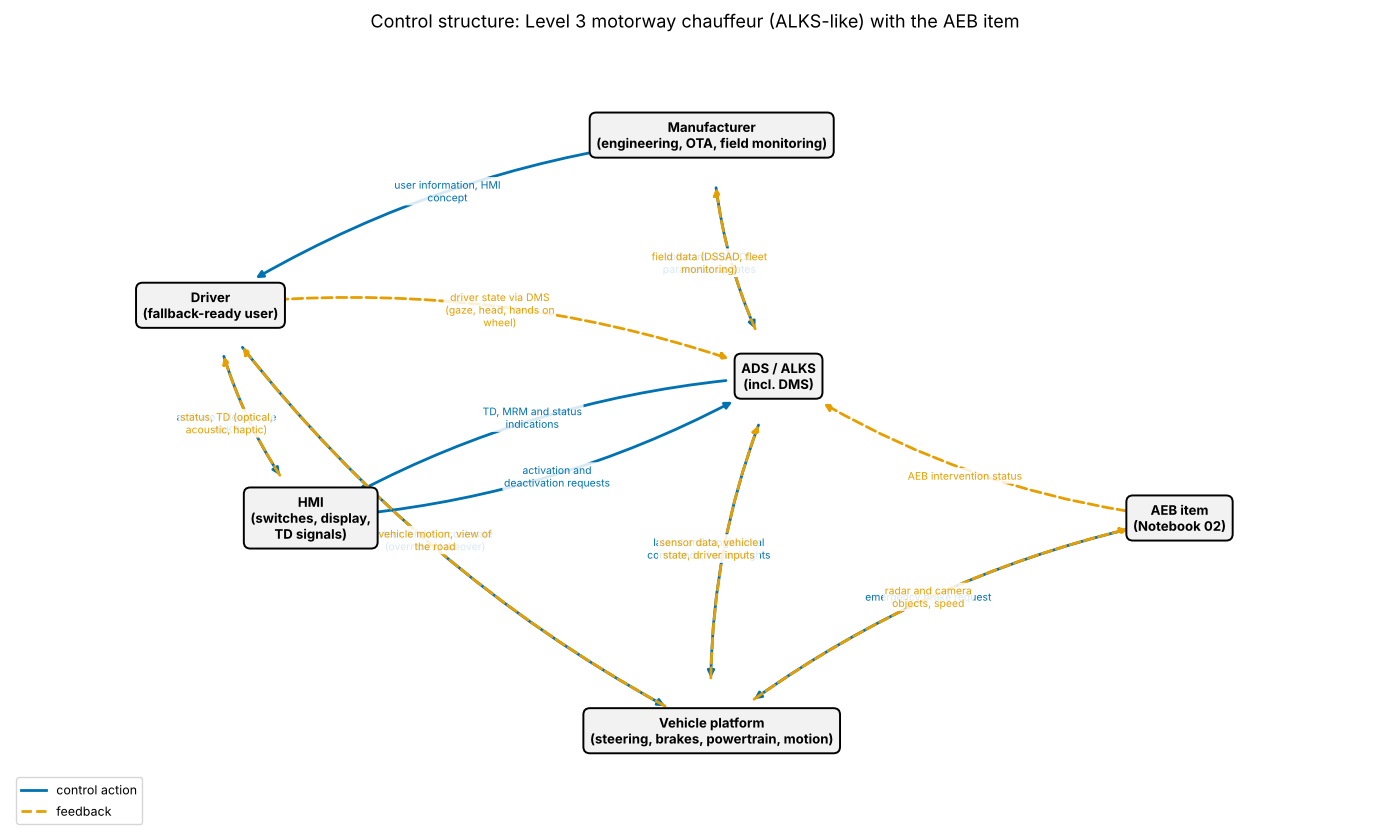

6 elements, 8 control actions, 7 feedback channels.


In [3]:
NODES = {  # name: (x, y, description)
    "Manufacturer": (3.0, 4.2, "Manufacturer\n(engineering, OTA, field monitoring)"),
    "Driver":       (0.0, 3.0, "Driver\n(fallback-ready user)"),
    "HMI":          (0.6, 1.5, "HMI\n(switches, display,\nTD signals)"),
    "ADS":          (3.4, 2.5, "ADS / ALKS\n(incl. DMS)"),
    "AEB":          (5.8, 1.5, "AEB item\n(Notebook 02)"),
    "Vehicle":      (3.0, 0.0, "Vehicle platform\n(steering, brakes, powertrain, motion)"),
}
EDGES = [  # (from, to, type, label)
    ("Manufacturer", "ADS", "control", "software and ODD parameter updates"),
    ("Manufacturer", "Driver", "control", "user information, HMI concept"),
    ("Driver", "HMI", "control", "activate / deactivate ALKS"),
    ("HMI", "ADS", "control", "activation and deactivation requests"),
    ("ADS", "HMI", "control", "TD, MRM and status indications"),
    ("Driver", "Vehicle", "control", "steer, brake, accelerate (override / takeover)"),
    ("ADS", "Vehicle", "control", "lateral and longitudinal commands, hazard lights"),
    ("AEB", "Vehicle", "control", "emergency brake request"),
    ("HMI", "Driver", "feedback", "status, TD (optical, acoustic, haptic)"),
    ("Vehicle", "Driver", "feedback", "vehicle motion, view of the road"),
    ("Driver", "ADS", "feedback", "driver state via DMS (gaze, head, hands on wheel)"),
    ("Vehicle", "ADS", "feedback", "sensor data, vehicle state, driver inputs"),
    ("Vehicle", "AEB", "feedback", "radar and camera objects, speed"),
    ("AEB", "ADS", "feedback", "AEB intervention status"),
    ("ADS", "Manufacturer", "feedback", "field data (DSSAD, fleet monitoring)"),
]

G = nx.MultiDiGraph()
for n, (x, y, desc) in NODES.items():
    G.add_node(n, pos=(x, y), desc=desc)
for u, v, kind, label in EDGES:
    G.add_edge(u, v, kind=kind, label=label)

def draw_control_structure(G, highlight=()):
    fig, ax = plt.subplots(figsize=(14, 8.5))
    pos = nx.get_node_attributes(G, "pos")
    for u, v, d in G.edges(data=True):
        control = d["kind"] == "control"
        colour = OI["red"] if (u, v) in highlight else (OI["blue"] if control else OI["orange"])
        rad = 0.12 if control else -0.12
        ax.annotate("", xy=pos[v], xytext=pos[u],
                    arrowprops=dict(arrowstyle="-|>", lw=2.0, color=colour, ls="-" if control else "--",
                                    shrinkA=38, shrinkB=38, connectionstyle=f"arc3,rad={rad}"))
        (x1, y1), (x2, y2) = pos[u], pos[v]
        mx, my = (x1 + x2) / 2, (y1 + y2) / 2
        nxv, nyv = (y2 - y1), -(x2 - x1)              # normal to the edge for the label offset
        norm = max(np.hypot(nxv, nyv), 1e-9)
        off = 0.22 * (1 if control else -1)
        ax.text(mx + off * nxv / norm, my + off * nyv / norm, "\n".join(textwrap.wrap(d["label"], 24)),
                fontsize=7.5, ha="center", va="center", color=colour,
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
    for n, (x, y) in pos.items():
        ax.text(x, y, G.nodes[n]["desc"], ha="center", va="center", fontsize=9.5, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.5", fc="#F2F2F2", ec="black", lw=1.4))
    ax.plot([], [], color=OI["blue"], lw=2, label="control action")
    ax.plot([], [], color=OI["orange"], lw=2, ls="--", label="feedback")
    if highlight:
        ax.plot([], [], color=OI["red"], lw=2, label="control action without feedback path")
    ax.legend(loc="lower left", fontsize=9)
    ax.set_xlim(-1.2, 7.0); ax.set_ylim(-0.7, 4.9); ax.axis("off")
    ax.set_title("Control structure: Level 3 motorway chauffeur (ALKS-like) with the AEB item", fontsize=13)
    plt.tight_layout(); plt.show()

draw_control_structure(G)
summary = pd.DataFrame(EDGES, columns=["From", "To", "Type", "Label"])
print(f"{G.number_of_nodes()} elements, {sum(summary.Type == 'control')} control actions, "
      f"{sum(summary.Type == 'feedback')} feedback channels.")

### 3.1 Process models

Every controller acts on its **process model**. Many loss scenarios in Step 4 are mismatches between a process model and reality, so we write the relevant beliefs down explicitly:

| Controller | Process-model variables that matter for safety |
|---|---|
| Driver | Is the ALKS active? Who is responsible for steering now? Is a TD running, and how much time is left? Is the vehicle inside the ODD? |
| ADS | Is the driver present, belted and available (R157 §6.1)? Is the driver attentive and holding the steering (§6.3.1.1)? Is the vehicle inside the ODD? Is the AEB intervening? Was the TD actually presented? |
| AEB | Is a collision imminent? Is the driver braking or steering? Is the ADS performing a manoeuvre? |
| Manufacturer | How does the fleet actually use the system (misuse, ODD exits, takeover performance)? |

### 3.2 Query the structure: control actions without a feedback path

A controller that cannot observe the effect of its action cannot detect when the action failed or was misunderstood. For every control edge $u \to v$ we look for a path of **feedback** edges from $v$ back to $u$.

,Controller,Controlled,Control action,Feedback path
0,Manufacturer,ADS,software and ODD parameter updates,ADS -> Manufacturer
1,Manufacturer,Driver,"user information, HMI concept",Driver -> ADS -> Manufacturer
2,Driver,HMI,activate / deactivate ALKS,HMI -> Driver
3,Driver,Vehicle,"steer, brake, accelerate (override / takeover)",Vehicle -> Driver
4,HMI,ADS,activation and deactivation requests,NONE
5,ADS,HMI,"TD, MRM and status indications",HMI -> Driver -> ADS
6,ADS,Vehicle,"lateral and longitudinal commands, hazard lights",Vehicle -> ADS
7,AEB,Vehicle,emergency brake request,Vehicle -> AEB


Control actions without any feedback path: 1
  HMI -> ADS: activation and deactivation requests


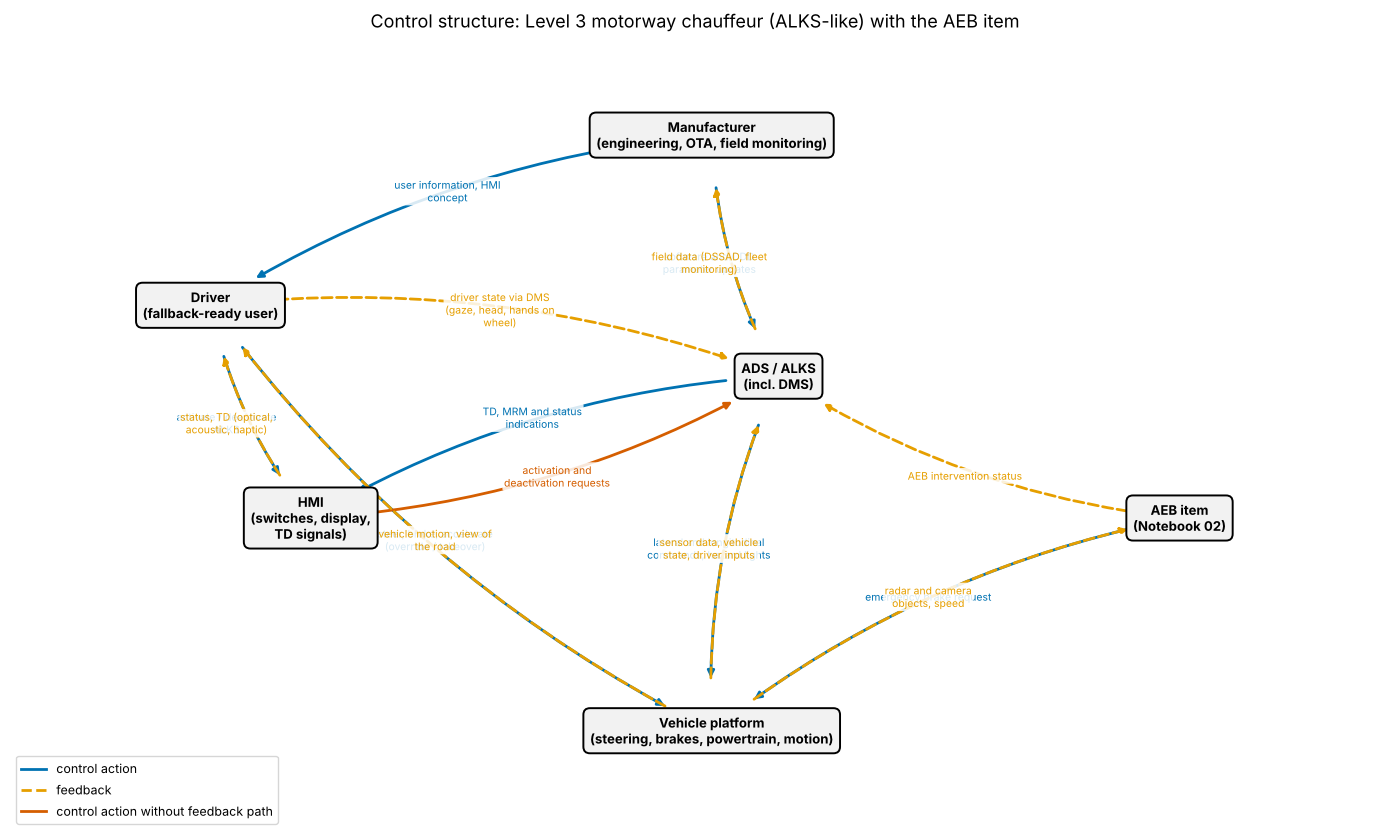

In [4]:
FB = nx.DiGraph([(u, v) for u, v, d in G.edges(data=True) if d["kind"] == "feedback"])
rows, missing = [], []
for u, v, d in G.edges(data=True):
    if d["kind"] != "control":
        continue
    path = nx.shortest_path(FB, v, u) if (v in FB and u in FB and nx.has_path(FB, v, u)) else None
    rows.append({"Controller": u, "Controlled": v, "Control action": d["label"],
                 "Feedback path": " -> ".join(path) if path else "NONE"})
    if path is None:
        missing.append((u, v))
fb_check = pd.DataFrame(rows)
display(fb_check)
print(f"Control actions without any feedback path: {len(missing)}")
for u, v in missing:
    print(f"  {u} -> {v}: {G.get_edge_data(u, v)[0]['label']}")
draw_control_structure(G, highlight=missing)

**Finding.** The query flags the ADS → HMI action (TD, MRM and status indications): in this structure the ADS commands the display and the warning signals but receives **no confirmation** that they were actually presented. A frozen display or a muted loudspeaker would leave the ADS believing that the driver has been warned. Its only indirect evidence is the driver's reaction seen by the DMS, which is ambiguous (no reaction may mean "not warned" or "not available"). This becomes loss scenario LS-6 in Section 5 and a requirement: *HMI elements that present safety-relevant signals shall report their health and the presentation of each TD to the ADS.*

The Manufacturer → Driver edge does have a path (the driver's state reaches the manufacturer only through DMS data and field monitoring); whether that path is adequate for detecting **misuse** at fleet level is a question for [Notebook 07-05](../07_Runtime_Assurance_and_Operations/05_field_safety_monitoring.ipynb).

## 4. Step 3: unsafe control actions, generated systematically

A UCA has five parts: **source controller, type, control action, context, link to hazards**. To make the analysis reviewable, we do not write UCAs freely. For each control action we define the **context variables** that matter, enumerate every combination of *UCA type × context*, and record an **explicit decision** for each: hazardous (with hazards) or not hazardous (with a reason). Code then checks that no combination is left undecided. This follows the context-table idea of the STPA Handbook.

The decision rules below are the analyst's judgement, written as small functions so that every decision is visible and testable.

In [5]:
UCA_TYPES = ["not provided", "provided", "too early / too late / wrong order", "stopped too soon / applied too long"]
H = lambda *ids: list(ids)           # shorthand for a hazard list
SAFE = lambda why: ([], why)         # explicit 'not hazardous' decision with its reason

def rule_td(t, c):                   # ADS: issue transition demand
    ev, drv = c["event"], c["driver"]
    if t == 0:
        return (H("H-3") if ev != "none" else []), ("system limit reached without handing over" if ev != "none"
                                                     else "no TD needed")
    if t == 1:
        if ev == "none" and drv == "unavailable":
            return H("H-4"), "spurious TD to an unavailable driver ends in an unnecessary MRM in a live lane"
        return SAFE("TD is required" if ev != "none" else "spurious TD with available driver: nuisance and trust (L-4), no hazard")
    if t == 2:
        return (H("H-3", "H-1") if ev in ("planned", "unplanned") else
                H("H-3") if ev == "failure" else []), ("lead time shorter than the driver's takeover time"
                                                       if ev != "none" else "no TD needed")
    return (H("H-3") if ev != "none" else []), ("TD withdrawn before the driver has taken over" if ev != "none"
                                                else "no TD running")

def rule_mrm(t, c):                  # ADS: initiate MRM
    s = c["situation"]
    table = {
        0: {"TD unanswered >= 10 s": (H("H-3"), "nobody drives once the system limit is reached"),
            "severe ALKS or vehicle failure": (H("H-3", "H-1"), "degraded ADS keeps driving"),
            "TD running < 10 s": SAFE("R157: MRM not yet allowed"), "driver has taken over": SAFE("not required"),
            "nominal operation": SAFE("not required")},
        1: {"nominal operation": (H("H-4"), "unnecessary stop in a live lane"),
            "driver has taken over": (H("H-5"), "MRM braking against the driver"),
            "TD running < 10 s": (H("H-4"), "premature MRM (R157 5.4.4.1: earliest 10 s after TD start)"),
            "TD unanswered >= 10 s": SAFE("required"), "severe ALKS or vehicle failure": SAFE("required")},
        2: {"TD unanswered >= 10 s": (H("H-3"), "MRM started late: vehicle runs past the system limit"),
            "severe ALKS or vehicle failure": (H("H-1", "H-3"), "late reaction to a severe failure"),
            "TD running < 10 s": SAFE("covered by 'provided'"), "driver has taken over": SAFE("covered by 'provided'"),
            "nominal operation": SAFE("covered by 'provided'")},
        3: {"TD unanswered >= 10 s": (H("H-3"), "MRM aborted before standstill without a driver"),
            "severe ALKS or vehicle failure": (H("H-3"), "MRM aborted before standstill without a driver"),
            "driver has taken over": (H("H-5"), "MRM continues after the driver took over"),
            "TD running < 10 s": SAFE("no MRM running"), "nominal operation": SAFE("no MRM running")},
    }
    return table[t][s]

def rule_decel(t, c):                # ADS: longitudinal deceleration
    threat, follower = c["threat"], c["follower"]
    if t in (0, 2):
        return (H("H-1") if threat else []), ("closing on a slower or stopped object" if threat else "no threat")
    if t == 1:
        return (H("H-4") if (not threat and follower) else []), \
               ("unexpected braking with close follower" if (not threat and follower) else
                "braking justified" if threat else "no follower affected")
    if threat:
        return H("H-1"), "braking released while the threat persists"
    return (H("H-4") if follower else []), ("braking held after the threat with close follower" if follower
                                            else "no follower affected")

def rule_aeb(t, c):                  # AEB: emergency brake request
    s = c["situation"]
    table = {
        0: {"collision imminent": (H("H-1"), "= HARA MB-01 (omission)"),
            "no threat, follower close": SAFE("not required"),
            "ADS performing evasive lane change": SAFE("ADS is resolving the conflict"),
            "driver already braking hard": SAFE("driver is braking")},
        1: {"no threat, follower close": (H("H-4"), "= HARA MB-02 (unintended braking, SG-01)"),
            "ADS performing evasive lane change": (H("H-5", "H-2"), "braking during an evasive manoeuvre destabilises it"),
            "collision imminent": SAFE("required"), "driver already braking hard": SAFE("raises deceleration, acceptable")},
        2: {"collision imminent": (H("H-1"), "= HARA MB-01 (too late)"),
            "no threat, follower close": SAFE("covered by 'provided'"),
            "ADS performing evasive lane change": SAFE("covered by 'provided'"),
            "driver already braking hard": SAFE("not hazardous")},
        3: {"collision imminent": (H("H-1"), "released before the threat is resolved"),
            "no threat, follower close": (H("H-4"), "= HARA MB-03 (held too long)"),
            "ADS performing evasive lane change": (H("H-5"), "conflict persists"),
            "driver already braking hard": SAFE("driver keeps braking")},
    }
    return table[t][s]

def rule_takeover(t, c):             # Driver: take over (hold the wheel, steer / brake)
    s = c["mode"]
    table = {
        0: {"TD running": (H("H-3", "H-4"), "no takeover: control gap, then MRM in a live lane"),
            "ALKS off (driver believes it is on)": (H("H-3", "H-2"), "mode confusion: nobody steers"),
            "ALKS active, no TD": SAFE("ADS drives"),
            "ADS emergency manoeuvre": SAFE("ADS resolves the conflict")},
        1: {"ADS emergency manoeuvre": (H("H-5", "H-1"), "driver input fights the emergency manoeuvre"),
            "ALKS active, no TD": (H("H-3"), "unintended override (e.g. knee on wheel) deactivates ALKS while driver is not ready"),
            "TD running": SAFE("required"), "ALKS off (driver believes it is on)": SAFE("required")},
        2: {"TD running": (H("H-3", "H-1"), "takeover after the system limit has been reached"),
            "ALKS off (driver believes it is on)": (H("H-2", "H-1"), "late recognition of the mode change"),
            "ALKS active, no TD": SAFE("not required"), "ADS emergency manoeuvre": SAFE("not required")},
        3: {"TD running": (H("H-3", "H-2"), "driver lets go again, expecting the ALKS to continue"),
            "ALKS off (driver believes it is on)": (H("H-2"), "driver lets go again, expecting lateral support"),
            "ALKS active, no TD": SAFE("not relevant"), "ADS emergency manoeuvre": SAFE("not relevant")},
    }
    return table[t][s]

def rule_activate(t, c):             # Driver: activate ALKS
    s = c["condition"]
    if t == 1 and s != "inside ODD, driver fit":
        return H("H-3"), ("activation outside the ODD (relies on the ADS refusing it)" if s.startswith("outside")
                          else "foreseeable misuse: driver intends to sleep or leave the seat")
    return SAFE("manual driving continues" if t == 0 else "intended use" if t == 1 else "not applicable to a discrete request")

def rule_deactivate(t, c):           # Driver: deliberately deactivate ALKS
    s = c["condition"]
    if t == 1 and s == "driver not in lateral control":
        return H("H-3", "H-2"), "deactivation while nobody steers (R157 6.2.4 requires lateral control)"
    if t == 1 and s == "ADS emergency manoeuvre":
        return H("H-1"), "deactivation in the middle of an emergency manoeuvre (R157 6.2.5.3 allows a delay)"
    return SAFE("not hazardous: ALKS keeps driving" if t == 0 else "intended use" if t == 1 else "discrete request")

def rule_status(t, c):               # ADS -> HMI: active-mode status indication
    s = c["state"]
    table = {
        0: {"ALKS active": SAFE("driver may take over unnecessarily; no hazard"),
            "ALKS just deactivated": (H("H-3", "H-2"), "deactivation not indicated: mode confusion"),
            "ALKS unavailable": SAFE("activation denied anyway")},
        1: {"ALKS just deactivated": (H("H-3", "H-2"), "stale 'active' indication after deactivation"),
            "ALKS unavailable": (H("H-3"), "'active' shown while the ALKS is not driving"),
            "ALKS active": SAFE("intended")},
        2: {"ALKS just deactivated": (H("H-3", "H-2"), "change of mode indicated late"),
            "ALKS active": SAFE("not hazardous"), "ALKS unavailable": SAFE("not hazardous")},
        3: {"ALKS just deactivated": (H("H-3"), "'active' indication persists"),
            "ALKS active": SAFE("indication flickers off: nuisance"), "ALKS unavailable": SAFE("not hazardous")},
    }
    return table[t][s]

def grid(**variables):
    keys = list(variables)
    return [dict(zip(keys, combo)) for combo in itertools.product(*variables.values())]

CONTROL_ACTIONS = [
    ("CA-1", "ADS", "issue a transition demand", grid(event=["none", "planned", "unplanned", "failure"],
                                                    driver=["available", "unavailable"]), rule_td),
    ("CA-2", "ADS", "initiate an MRM", grid(situation=["nominal operation", "TD running < 10 s", "TD unanswered >= 10 s",
                                                       "severe ALKS or vehicle failure", "driver has taken over"]), rule_mrm),
    ("CA-3", "ADS", "command deceleration", grid(threat=[True, False], follower=[True, False]), rule_decel),
    ("CA-4", "AEB", "request emergency braking", grid(situation=["collision imminent", "no threat, follower close",
                                                                 "ADS performing evasive lane change",
                                                                 "driver already braking hard"]), rule_aeb),
    ("CA-5", "Driver", "take over (hold the wheel, steer or brake)",
     grid(mode=["TD running", "ALKS active, no TD", "ALKS off (driver believes it is on)", "ADS emergency manoeuvre"]),
     rule_takeover),
    ("CA-6", "Driver", "activate the ALKS", grid(condition=["inside ODD, driver fit", "outside ODD (e.g. heavy rain)",
                                                            "driver intends to sleep or leave the seat"]), rule_activate),
    ("CA-7", "Driver", "deactivate the ALKS", grid(condition=["driver attentive, hands on wheel",
                                                              "driver not in lateral control", "ADS emergency manoeuvre"]),
     rule_deactivate),
    ("CA-8", "ADS", "show the active-mode indication", grid(state=["ALKS active", "ALKS just deactivated",
                                                                   "ALKS unavailable"]), rule_status),
]

def context_text(c):
    return ", ".join(f"{k}={v}" if not isinstance(v, bool) else (k if v else f"no {k}") for k, v in c.items())

rows = []
for ca_id, ctrl, action, contexts, rule in CONTROL_ACTIONS:
    for t, ctx in itertools.product(range(4), contexts):
        hz, why = rule(t, ctx)
        rows.append({"CA": ca_id, "Controller": ctrl, "Control action": action, "Type": UCA_TYPES[t],
                     "Context": context_text(ctx), "Hazards": hz, "Rationale": why})
candidates = pd.DataFrame(rows)

# Completeness and consistency checks
assert candidates["Rationale"].str.len().gt(0).all(), "every combination needs a written decision"
assert all(set(h) <= set(hazards.index) for h in candidates["Hazards"]), "unknown hazard ID"
ucas = candidates[candidates["Hazards"].str.len() > 0].reset_index(drop=True)
ucas.insert(0, "UCA", [f"UCA-{i + 1:02d}" for i in range(len(ucas))])

print(f"Combinations examined: {len(candidates)}; decided hazardous: {len(ucas)}; "
      f"decided not hazardous (with reason): {len(candidates) - len(ucas)}")
display(pd.crosstab(ucas["Controller"] + ": " + ucas["Control action"], ucas["Type"], margins=True))

Combinations examined: 136; decided hazardous: 61; decided not hazardous (with reason): 75


Type,not provided,provided,stopped too soon / applied too long,too early / too late / wrong order,All
row_0,,,,,
ADS: command deceleration,2,1,3,2,8
ADS: initiate an MRM,2,3,3,2,10
ADS: issue a transition demand,6,1,6,6,19
ADS: show the active-mode indication,1,2,1,1,5
AEB: request emergency braking,1,2,3,1,7
Driver: activate the ALKS,0,2,0,0,2
Driver: deactivate the ALKS,0,2,0,0,2
"Driver: take over (hold the wheel, steer or brake)",2,2,2,2,8
All,14,15,18,14,61


In [6]:
cols = ["UCA", "Controller", "Type", "Control action", "Context", "Hazards", "Rationale"]
display(ucas[cols])
hz_counts = ucas.explode("Hazards")["Hazards"].value_counts().reindex(hazards.index, fill_value=0)
print("UCAs per hazard:", ", ".join(f"{h}: {n}" for h, n in hz_counts.items()))
uncovered = [h for h, n in hz_counts.items() if n == 0]
print("Hazards without any UCA:", uncovered or "none")

,UCA,Controller,Type,Control action,Context,Hazards,Rationale
0,UCA-01,ADS,not provided,issue a transition demand,"event=planned, driver=available",[H-3],system limit reached without handing over
1,UCA-02,ADS,not provided,issue a transition demand,"event=planned, driver=unavailable",[H-3],system limit reached without handing over
2,UCA-03,ADS,not provided,issue a transition demand,"event=unplanned, driver=available",[H-3],system limit reached without handing over
3,UCA-04,ADS,not provided,issue a transition demand,"event=unplanned, driver=unavailable",[H-3],system limit reached without handing over
4,UCA-05,ADS,not provided,issue a transition demand,"event=failure, driver=available",[H-3],system limit reached without handing over
...,...,...,...,...,...,...,...
56,UCA-57,ADS,not provided,show the active-mode indication,state=ALKS just deactivated,"[H-3, H-2]",deactivation not indicated: mode confusion
57,UCA-58,ADS,provided,show the active-mode indication,state=ALKS just deactivated,"[H-3, H-2]",stale 'active' indication after deactivation
58,UCA-59,ADS,provided,show the active-mode indication,state=ALKS unavailable,[H-3],'active' shown while the ALKS is not driving
59,UCA-60,ADS,too early / too late / wrong order,show the active-mode indication,state=ALKS just deactivated,"[H-3, H-2]",change of mode indicated late


UCAs per hazard: H-1: 19, H-2: 9, H-3: 37, H-4: 8, H-5: 5
Hazards without any UCA: none


**Reading the table.** About half of the examined combinations are hazardous. The not-hazardous decisions are as important for the review as the UCAs: each carries its reason, so a reviewer can disagree with a specific line instead of with the whole analysis. **H-3 (control authority gap)** collects the largest number of UCAs, and it is reached through *three different controllers*: the ADS (TD late or withdrawn, MRM not started), the driver (no or late takeover, letting go again) and the HMI path (mode indication wrong). No single-component analysis would bring these together.

### 4.1 Controller constraints

Each UCA is inverted into a **controller constraint**, the requirement that prevents it. The templates below follow the UCA types; the engineer then sharpens the wording and adds the numbers.

In [7]:
def constraint(row):
    who, act, ctx, t = row["Controller"], row["Control action"], row["Context"], row["Type"]
    if t == "not provided":
        return f"{who} must {act} when {ctx}."
    if t == "provided":
        return f"{who} must not {act} when {ctx}."
    if t.startswith("too early"):
        return f"{who} must {act} within the required time when {ctx} (timing requirement to be quantified)."
    return f"{who} must neither stop '{act}' too soon nor hold it too long when {ctx}."

ucas["Controller constraint"] = ucas.apply(constraint, axis=1)
display(ucas[["UCA", "Controller constraint", "Hazards"]].head(12))
print(f"{len(ucas)} controller constraints derived (first 12 shown).")

# Quantifying one timing constraint: UCA 'TD too late' needs a number. The lead time must cover the
# driver's takeover time AND, for planned events, the R157 MRM fallback (para 5.4.2.1).
v, a_mrm, t_mrm_earliest = 130 / 3.6, 4.0, 10.0
t_stop = v / a_mrm
print(f"\nPlanned event at 130 km/h: TD must start >= {t_mrm_earliest:.0f} s + {t_stop:.1f} s "
      f"= {t_mrm_earliest + t_stop:.1f} s ({v * t_mrm_earliest + v**2 / (2 * a_mrm):.0f} m) before the event, "
      "so that an MRM at <= 4 m/s^2 could still stop the vehicle in time.")

,UCA,Controller constraint,Hazards
0,UCA-01,"ADS must issue a transition demand when event=planned, driver=available.",[H-3]
1,UCA-02,"ADS must issue a transition demand when event=planned, driver=unavailable.",[H-3]
2,UCA-03,"ADS must issue a transition demand when event=unplanned, driver=available.",[H-3]
3,UCA-04,"ADS must issue a transition demand when event=unplanned, driver=unavailable.",[H-3]
4,UCA-05,"ADS must issue a transition demand when event=failure, driver=available.",[H-3]
5,UCA-06,"ADS must issue a transition demand when event=failure, driver=unavailable.",[H-3]
6,UCA-07,"ADS must not issue a transition demand when event=none, driver=unavailable.",[H-4]
7,UCA-08,"ADS must issue a transition demand within the required time when event=planned, driver=available (timing r...","[H-3, H-1]"
8,UCA-09,"ADS must issue a transition demand within the required time when event=planned, driver=unavailable (timing...","[H-3, H-1]"
9,UCA-10,"ADS must issue a transition demand within the required time when event=unplanned, driver=available (timing...","[H-3, H-1]"


61 controller constraints derived (first 12 shown).

Planned event at 130 km/h: TD must start >= 10 s + 9.0 s = 19.0 s (524 m) before the event, so that an MRM at <= 4 m/s^2 could still stop the vehicle in time.


The last line shows how STPA hands over to quantitative work: the UCA "TD provided too late" becomes a timing constraint, and its number comes from UN R157 (§5.4.2.1, §5.4.4.1, §5.5.2) and from takeover-time evidence, which [Notebook 07-03](../07_Runtime_Assurance_and_Operations/03_human_factors_and_takeover.ipynb) derives from published studies.

## 5. Step 4: loss scenarios

A loss scenario explains **why** a UCA could occur, or why a correct control action could still lead to a hazard. The Handbook organises the search around the control loop:

- **(a) Why would the controller issue the UCA?** Failures of the controller; an inadequate control algorithm; unsafe control inputs; an **inadequate process model**, usually because feedback is missing, delayed, wrong or misread.
- **(b) Why would a correct action be executed improperly?** Problems in the control path (actuator, communication) or in the controlled process (disturbances, other controllers acting on it).

Two scenario families dominate for Level 3: **mode confusion** (the driver's process model of the automation mode is wrong) and **takeover failure** (the driver's state does not match the ADS's process model or the lead time).

In [8]:
def uca_id(ca, type_prefix, context_part):
    hit = ucas[(ucas.CA == ca) & ucas.Type.str.startswith(type_prefix) & ucas.Context.str.contains(context_part, regex=False)]
    assert len(hit) >= 1, (ca, type_prefix, context_part)
    return hit.UCA.iloc[0]

scenarios = pd.DataFrame([
    ("LS-1", uca_id("CA-5", "not provided", "ALKS off"), "(a) process model: mode confusion",
     "With one hand on the wheel, the driver brakes briefly to open the gap to a cutting-in vehicle; under R157 "
     "6.2.5.1(b) this deactivates the ALKS. The active-mode indication disappears and a chime sounds while the "
     "driver watches the cut-in. The driver believes the ALKS will resume, lets go of the wheel and the vehicle drifts.",
     "Distinct multimodal deactivation feedback; hands-off detection right after any deactivation with escalating warning; "
     "review which driver inputs deactivate the system."),
    ("LS-2", uca_id("CA-5", "too early", "TD running"), "(a) process model + algorithm: takeover",
     "Driver is engaged in a permitted non-driving task. The TD for an unplanned event (e.g. lane markings ending at "
     "road works) arrives with a lead time that covers the median but not the slow tail of takeover times.",
     "Lead time requirement from the takeover-time distribution (95th/99th percentile, not the mean); "
     "detect unplanned events earlier; reduce speed during the transition phase (R157 5.4.3)."),
    ("LS-3", uca_id("CA-1", "too early", "planned"), "(a) control algorithm",
     "The exit is known from the route, but the TD timing logic uses a fixed distance and ignores congestion "
     "that reduces the reachable stopping places.",
     "TD timing computed from R157 5.4.2.1 (MRM must be able to stop before the planned event) with current traffic."),
    ("LS-4", uca_id("CA-2", "not provided", "TD unanswered"), "(a) process model: feedback wrong",
     "Driver has fallen asleep, but the DMS still counts head movements caused by road vibration as an availability "
     "criterion, so the ADS believes the driver is available and keeps waiting for a takeover.",
     "Independence and validation of the two availability criteria (R157 6.1.3.1); MRM after 10 s regardless of "
     "the DMS verdict when the TD is not answered."),
    ("LS-5", uca_id("CA-4", "provided", "evasive"), "(b) other controller acting on the process",
     "During an ADS evasive lane change around debris, the AEB detects the debris as an imminent obstacle and "
     "brakes hard. Neither controller knows the other's intention.",
     "Arbitration between AEB and ADS (SC-5); ADS publishes its planned trajectory to the AEB; "
     "joint validation of both items."),
    ("LS-6", uca_id("CA-1", "stopped too soon", "unplanned"), "(a) feedback missing (found in 3.2)",
     "The TD is issued, but the HMI display has frozen and the loudspeaker is muted by an infotainment fault. "
     "The ADS has no feedback that the TD was presented and attributes the missing reaction to the driver.",
     "HMI health and presentation acknowledgement to the ADS; escalation over an independent channel (haptic, "
     "R157 6.4.1(c)); fault of the TD path treated as a severe ALKS failure."),
    ("LS-7", uca_id("CA-6", "provided", "sleep"), "(a) controller (driver) intention: foreseeable misuse",
     "Driver activates the ALKS intending to sleep on a long motorway journey, having learned that "
     "warnings can be acknowledged by small head movements.",
     "Misuse analysis per ISO 21448 (see Notebook 07-03): robust availability criteria, escalation, "
     "repeated-misuse lockout, user information."),
    ("LS-8", uca_id("CA-3", "provided", "no threat"), "(a) process model: perception insufficiency",
     "A gantry shadow is classified as a stationary obstacle (a SOTIF triggering condition); the ADS brakes with a "
     "close follower.",
     "SOTIF analysis of the perception (Module 04), plausibility with a second modality, deceleration limits "
     "when confidence is low."),
], columns=["ID", "UCA", "Causal category", "Scenario", "Requirement / mitigation"])
scenarios = scenarios.merge(ucas[["UCA", "Controller", "Control action", "Type", "Hazards"]], on="UCA")
display(scenarios[["ID", "UCA", "Controller", "Type", "Causal category", "Hazards"]])
for _, s in scenarios.iterrows():
    print(f"{s.ID} ({s.UCA}, {s['Causal category']}):\n  " + "\n  ".join(textwrap.wrap(s.Scenario, 110)))
    print("  -> " + "\n     ".join(textwrap.wrap(s["Requirement / mitigation"], 107)))
n_nofail = scenarios["Causal category"].str.contains("process model|algorithm|intention|other controller").sum()
print(f"\n{n_nofail} of {len(scenarios)} scenarios need no component failure at all.")

,ID,UCA,Controller,Type,Causal category,Hazards
0,LS-1,UCA-46,Driver,not provided,(a) process model: mode confusion,"[H-3, H-2]"
1,LS-2,UCA-49,Driver,too early / too late / wrong order,(a) process model + algorithm: takeover,"[H-3, H-1]"
2,LS-3,UCA-08,ADS,too early / too late / wrong order,(a) control algorithm,"[H-3, H-1]"
3,LS-4,UCA-20,ADS,not provided,(a) process model: feedback wrong,[H-3]
4,LS-5,UCA-40,AEB,provided,(b) other controller acting on the process,"[H-5, H-2]"
5,LS-6,UCA-16,ADS,stopped too soon / applied too long,(a) feedback missing (found in 3.2),[H-3]
6,LS-7,UCA-54,Driver,provided,(a) controller (driver) intention: foreseeable misuse,[H-3]
7,LS-8,UCA-32,ADS,provided,(a) process model: perception insufficiency,[H-4]


LS-1 (UCA-46, (a) process model: mode confusion):
  With one hand on the wheel, the driver brakes briefly to open the gap to a cutting-in vehicle; under R157
  6.2.5.1(b) this deactivates the ALKS. The active-mode indication disappears and a chime sounds while the
  driver watches the cut-in. The driver believes the ALKS will resume, lets go of the wheel and the vehicle
  drifts.
  -> Distinct multimodal deactivation feedback; hands-off detection right after any deactivation with escalating
     warning; review which driver inputs deactivate the system.
LS-2 (UCA-49, (a) process model + algorithm: takeover):
  Driver is engaged in a permitted non-driving task. The TD for an unplanned event (e.g. lane markings ending at
  road works) arrives with a lead time that covers the median but not the slow tail of takeover times.
  -> Lead time requirement from the takeover-time distribution (95th/99th percentile, not the mean); detect
     unplanned events earlier; reduce speed during the trans

### 5.1 Mode confusion as a structural property

Research on supervisory control (Sarter & Woods, 1995; Leveson, 2011) identifies conditions under which operators lose track of the automation mode. Three are easy to check for each mode transition:

1. **Indirect transition**: the mode changes without an explicit command to change mode (initiated by the system, or as a *side effect* of a driver input meant for something else).
2. **Weak feedback**: the change is signalled only optically.
3. **No immediate bodily cue**: the vehicle behaves the same for a while after the transition (e.g. it keeps the lane for a few seconds by inertia), so the driver's perception of motion does not reveal the change.

The table lists the ALKS transitions with the feedback that UN R157 (01 series) requires for them, plus one Level 2 transition for comparison. The score is a screening heuristic (one point per condition), not a validated metric.

In [9]:
transitions = pd.DataFrame([
    # (from, to, trigger, indirect?, feedback required, immediate motion cue?)
    ("OFF", "ACTIVE", "driver activates deliberately (6.2.3)", False, "optical status indication (6.4.2.2)", False),
    ("ACTIVE", "OFF", "driver deactivates deliberately (6.2.4)", False, "optical + acoustic (6.4.2.3)", False),
    ("ACTIVE", "OFF", "side effect of steering / braking override (6.2.5.1)", True, "optical + acoustic (6.4.2.3)", False),
    ("ACTIVE", "TD", "system limit reached (5.4)", True, "optical + acoustic/haptic; haptic at the latest after 4 s (6.4.1)", False),
    ("TD", "OFF", "driver takes over, attentive (6.2.5.2)", False, "optical; acoustic not required after an acoustic TD (6.4.2.3)", True),
    ("TD", "MRM", "no response, >= 10 s (5.4.4.1)", True, "optical + acoustic/haptic (6.4.1(d)); hazard lights", True),
    ("ACTIVE", "MRM", "severe ALKS or vehicle failure (5.4.4.1.1)", True, "optical + acoustic/haptic (6.4.1(d))", True),
    ("L2 ACTIVE", "L2 OFF", "Level 2 lane centring cancels (e.g. lines lost) - manufacturer-specific", True,
     "manufacturer-specific (often optical + chime)", False),
], columns=["From", "To", "Trigger (R157 paragraph)", "Indirect", "Feedback", "Motion cue"])

transitions["Weak feedback"] = ~transitions["Feedback"].str.contains("acoustic|haptic")
transitions["Score"] = (transitions["Indirect"].astype(int) + transitions["Weak feedback"].astype(int)
                        + (~transitions["Motion cue"]).astype(int))
display(transitions.sort_values("Score", ascending=False))
flag = transitions[transitions.Score >= 2]
print("Transitions to examine for mode confusion (score >= 2):")
for _, r in flag.iterrows():
    print(f"  {r.From} -> {r.To}: {r['Trigger (R157 paragraph)']} (score {r.Score})")

,From,To,Trigger (R157 paragraph),Indirect,Feedback,Motion cue,Weak feedback,Score
7,L2 ACTIVE,L2 OFF,Level 2 lane centring cancels (e.g. lines lost) - manufacturer-specific,True,manufacturer-specific (often optical + chime),False,True,3
0,OFF,ACTIVE,driver activates deliberately (6.2.3),False,optical status indication (6.4.2.2),False,True,2
3,ACTIVE,TD,system limit reached (5.4),True,optical + acoustic/haptic; haptic at the latest after 4 s (6.4.1),False,False,2
2,ACTIVE,OFF,side effect of steering / braking override (6.2.5.1),True,optical + acoustic (6.4.2.3),False,False,2
1,ACTIVE,OFF,driver deactivates deliberately (6.2.4),False,optical + acoustic (6.4.2.3),False,False,1
5,TD,MRM,"no response, >= 10 s (5.4.4.1)",True,optical + acoustic/haptic (6.4.1(d)); hazard lights,True,False,1
6,ACTIVE,MRM,severe ALKS or vehicle failure (5.4.4.1.1),True,optical + acoustic/haptic (6.4.1(d)),True,False,1
4,TD,OFF,"driver takes over, attentive (6.2.5.2)",False,optical; acoustic not required after an acoustic TD (6.4.2.3),True,False,0


Transitions to examine for mode confusion (score >= 2):
  OFF -> ACTIVE: driver activates deliberately (6.2.3) (score 2)
  ACTIVE -> OFF: side effect of steering / braking override (6.2.5.1) (score 2)
  ACTIVE -> TD: system limit reached (5.4) (score 2)
  L2 ACTIVE -> L2 OFF: Level 2 lane centring cancels (e.g. lines lost) - manufacturer-specific (score 3)


The screening points at the same transitions that appear in field data. The NHTSA recall of Tesla's Autosteer (23V-838, December 2023) describes the consequence of the defect as a driver who "fails to recognize when Autosteer is canceled or not engaged" ([NHTSA recall record](https://www.nhtsa.gov/recalls?nhtsaId=23V838)), and NHTSA's follow-up query RQ24-009 explicitly names **mode confusion** among the issues the remedy must address. [Notebook 07-03](../07_Runtime_Assurance_and_Operations/03_human_factors_and_takeover.ipynb) takes this case further.

The ALKS rules are visibly designed against mode confusion: R157 forbids an automatic fall-back to a Level 2 function after deactivation (§6.2.6), requires an acoustic signal on deactivation unless the TD already had one (§6.4.2.3), and requires the driver to hold the steering control at deliberate deactivation (§6.2.4). STPA lets you show *why* each rule is there, and check whether your HMI concept meets the intent and not only the letter.

## 6. STPA, HARA and FTA on the same item

We now take only the AEB part of the analysis and compare it with the HARA of [Notebook 02](02_hara.ipynb) (malfunctioning behaviours MB-01 omission, MB-02 unintended braking, MB-03 braking too strong or too long) and with the fault tree of [Notebook 04](04_fault_tree_analysis.ipynb) (top event: unintended full braking).

In [10]:
HARA_MB = {"MB-01": "No or insufficient AEB deceleration when a collision is imminent",
           "MB-02": "Unintended AEB deceleration without a collision threat",
           "MB-03": "AEB deceleration stronger or longer than required"}

aeb = ucas[ucas.CA == "CA-4"].copy()
aeb["HARA counterpart"] = aeb["Rationale"].str.extract(r"(MB-0\d)")[0].fillna("none")
display(aeb[["UCA", "Type", "Context", "Hazards", "HARA counterpart"]])
mapped = (aeb["HARA counterpart"] != "none").sum()
print(f"AEB UCAs: {len(aeb)}; with a HARA malfunctioning behaviour: {mapped}; without: {len(aeb) - mapped}")
for _, r in aeb[aeb["HARA counterpart"] == "none"].iterrows():
    print(f"  {r.UCA}: {r.Type} in context '{r.Context}' -> {r.Hazards} ({r.Rationale})")

# UCAs of other controllers that act on the same physical outcome (braking / separation)
related = ucas[(ucas.CA != "CA-4") & ucas.Hazards.apply(lambda h: bool({"H-1", "H-4", "H-5"} & set(h)))]
print(f"\nUCAs of other controllers that can produce the same vehicle-level hazards: {len(related)} "
      f"({', '.join(sorted(related.Controller.unique()))}). A HARA of the AEB item alone does not contain them.")

,UCA,Type,Context,Hazards,HARA counterpart
37,UCA-38,not provided,situation=collision imminent,[H-1],MB-01
38,UCA-39,provided,"situation=no threat, follower close",[H-4],MB-02
39,UCA-40,provided,situation=ADS performing evasive lane change,"[H-5, H-2]",none
40,UCA-41,too early / too late / wrong order,situation=collision imminent,[H-1],MB-01
41,UCA-42,stopped too soon / applied too long,situation=collision imminent,[H-1],none
42,UCA-43,stopped too soon / applied too long,"situation=no threat, follower close",[H-4],MB-03
43,UCA-44,stopped too soon / applied too long,situation=ADS performing evasive lane change,[H-5],none


AEB UCAs: 7; with a HARA malfunctioning behaviour: 4; without: 3
  UCA-40: provided in context 'situation=ADS performing evasive lane change' -> ['H-5', 'H-2'] (braking during an evasive manoeuvre destabilises it)
  UCA-42: stopped too soon / applied too long in context 'situation=collision imminent' -> ['H-1'] (released before the threat is resolved)
  UCA-44: stopped too soon / applied too long in context 'situation=ADS performing evasive lane change' -> ['H-5'] (conflict persists)

UCAs of other controllers that can produce the same vehicle-level hazards: 24 (ADS, Driver). A HARA of the AEB item alone does not contain them.


| | **HARA** (ISO 26262-3) | **FTA** (ISO 26262-9, IEC 61025) | **STPA** |
|---|---|---|---|
| Question | Which malfunctions of the item are how risky? | Which combinations of faults cause this top event, and how likely? | Which control actions are unsafe in which context, and why could they occur? |
| Model of causation | Malfunctioning behaviour of the item | Boolean combination of component faults | Inadequate control in a control structure |
| Scope | One item, vehicle level | One top event, down to basic events | Whole sociotechnical system: driver, HMI, several items, manufacturer |
| Finds well | Risk ranking (ASIL), safety goals | Single points of failure, common causes, probabilities | Interaction hazards, mode confusion, timing, missing feedback, misuse, requirements on the human-automation interface |
| Misses | Causes; interactions between items; human process models | Hazards without a failure; human decisions; timing | Probabilities; detailed hardware fault coverage; it does not assign ASILs |
| AEB example | MB-01/02/03 with ASIL B and D | Cut sets of "unintended full braking" | MB-01/02/03 again, **plus** AEB braking during an ADS evasive manoeuvre and conflicts with the driver |

The methods are **complementary**, not competitors. A pragmatic order in a project: STPA early on the concept (it needs no detailed design and produces requirements), HARA to rate and set ASILs, FTA/FMEA on the architecture to show the safety goals are met by the hardware and software.

## 7. STPA-Sec: the same structure for security

**STPA-Sec** (Young & Leveson, 2014) applies the same steps with an attacker as an additional source of unsafe control: the analysis still starts from **losses** and the control structure, and asks how an adversary could make a UCA happen, typically by **injecting, blocking, delaying or falsifying** control actions and feedback. Starting from losses keeps the security analysis focused on what matters for safety rather than on every possible vulnerability.

We generate the candidate adversarial manipulations directly from the control-structure graph.

In [11]:
MANIPULATIONS = {"control": ["inject / spoof", "block / delay"],
                 "feedback": ["falsify", "block / delay"]}
sec = pd.DataFrame([{"Edge": f"{u} -> {v}", "Kind": d["kind"], "Signal": d["label"], "Manipulation": m}
                    for u, v, d in G.edges(data=True) for m in MANIPULATIONS[d["kind"]]])
print(f"Candidate manipulations generated from {G.number_of_edges()} edges: {len(sec)}")

# Link a few manipulations to UCAs they would cause (the analyst's step)
sec_links = pd.DataFrame([
    ("Driver -> ADS", "falsify", uca_id("CA-2", "not provided", "TD unanswered"),
     "Spoofed DMS signal (e.g. image injected into the driver camera) keeps the driver 'available' while asleep"),
    ("HMI -> ADS", "inject / spoof", uca_id("CA-7", "provided", "not in lateral control"),
     "Injected deactivation request on the vehicle bus while the driver does not hold the wheel"),
    ("Vehicle -> ADS", "falsify", uca_id("CA-1", "not provided", "unplanned"),
     "Spoofed GNSS / map position hides the end of the ODD, so no TD is issued"),
    ("ADS -> HMI", "block / delay", uca_id("CA-8", "not provided", "just deactivated"),
     "Compromised infotainment suppresses the deactivation indication"),
    ("Manufacturer -> ADS", "inject / spoof", uca_id("CA-2", "provided", "nominal"),
     "Malicious software update triggers MRMs in live lanes"),
], columns=["Edge", "Manipulation", "Causes UCA", "Threat scenario"])
assert set(zip(sec_links.Edge, sec_links.Manipulation)) <= set(zip(sec.Edge, sec.Manipulation))
display(sec_links)
print("Each linked manipulation becomes a threat scenario in the ISO/SAE 21434 TARA with the safety impact "
      "already justified by the UCA -> hazard -> loss chain.")

Candidate manipulations generated from 15 edges: 30

,Edge,Manipulation,Causes UCA,Threat scenario
0,Driver -> ADS,falsify,UCA-20,Spoofed DMS signal (e.g. image injected into the driver camera) keeps the driver 'available' while asleep
1,HMI -> ADS,inject / spoof,UCA-55,Injected deactivation request on the vehicle bus while the driver does not hold the wheel
2,Vehicle -> ADS,falsify,UCA-03,"Spoofed GNSS / map position hides the end of the ODD, so no TD is issued"
3,ADS -> HMI,block / delay,UCA-57,Compromised infotainment suppresses the deactivation indication
4,Manufacturer -> ADS,inject / spoof,UCA-22,Malicious software update triggers MRMs in live lanes


Each linked manipulation becomes a threat scenario in the ISO/SAE 21434 TARA with the safety impact already justified by the UCA -> hazard -> loss chain.


The link to [Module 05 · TARA](../05_Cybersecurity_ISO21434/02_tara.ipynb): the TARA rates feasibility and impact; STPA-Sec supplies **which** manipulations of **which** signals are safety-relevant and why. The spoofed-DMS scenario also connects to ISO/PAS 8800 (an ML-based driver camera) and to UN R155 type approval.

## 8. Where STPA sits in the standards

- **ISO 26262:2018** requires hazards to be identified systematically (Part 3) and safety analyses at system level (Part 9, clause 8), without prescribing STPA. STPA can supply the hazard list and the control-related causes that feed the HARA and the functional safety concept; it does not replace the S/E/C rating or the hardware metrics.
- **ISO 21448:2022 (SOTIF)** names STPA as one approach for the systematic identification of hazards and triggering conditions and illustrates it in an informative annex (Annex B.4, as cited by Graubohm et al., 2023). Loss scenarios with an *inadequate process model* are exactly SOTIF's functional insufficiencies, and driver-related scenarios are its **reasonably foreseeable misuse**.
- **SAE J3187** gives recommended practices for applying STPA. It was issued in February 2022 for automotive safety-critical systems and revised in May 2023 (J3187_202305) with a scope widened to safety-critical systems in any industry; appendices published in 2023 cover STPA for human-machine interactions (J3187-1) and STPA with SOTIF (J3187-2) (SAE Mobilus and retailer listings, as of October 2026).
- **UN R157** names STPA explicitly. In the Annex 4 audit, the system-level safety approach "may be based on" FMEA, FTA and STPA "or any similar process" (Annex 4, §3.4.4(b)), and the inspection must cover, among other items, interactions with other vehicle systems such as braking and steering (i), reasonably foreseeable misuse, driver mistakes such as unintentional override, and tampering (vi), and cyber-attacks with a safety impact (viii). §5.1.8 requires measures against reasonably foreseeable misuse. Each of these items is a column of the analysis above.

STPA has been applied to automated-driving architectures in published case studies, e.g. Abdulkhaleq et al. (2017) for a fully automated vehicle architecture and Graubohm et al. (2023) for SOTIF triggering conditions.

## 9. Exercise: add the lane-change control action

The 01 series of UN R157 allows the ALKS to change lanes (regular lane changes and MRM lane changes). Add a control action **CA-9 "ADS: perform a lane change"** with the context variables `target_lane` ∈ {free, vehicle approaching fast from behind} and `td_state` ∈ {no TD, TD running}. Write `rule_lc(t, c)`, regenerate the UCA table and answer:

1. How many new UCAs do you obtain, and which hazards do they link to?
2. Which R157 provision addresses the UCA "lane change *provided* while a TD is running"?

In [12]:
# Exercise scaffold: complete rule_lc and run the cell (it runs as is with a placeholder rule)
def rule_lc(t, c):
    # return (hazard list, rationale); start with everything 'not decided' and replace
    return SAFE("TODO: decide")

lc_contexts = grid(target_lane=["free", "vehicle approaching fast from behind"], td_state=["no TD", "TD running"])
lc = pd.DataFrame([{"Type": UCA_TYPES[t], "Context": context_text(c), "Hazards": rule_lc(t, c)[0],
                    "Rationale": rule_lc(t, c)[1]} for t, c in itertools.product(range(4), lc_contexts)])
print(f"{len(lc)} combinations; hazardous so far: {(lc.Hazards.str.len() > 0).sum()}")

16 combinations; hazardous so far: 0


<details>
<summary>Example solution</summary>

```python
def rule_lc(t, c):
    fast, td = c["target_lane"].startswith("vehicle"), c["td_state"] == "TD running"
    if t == 0:
        return SAFE("staying in lane is acceptable (MRM lane change is a separate decision)")
    if t == 1 and fast:
        return H("H-1"), "cuts in front of a fast vehicle"
    if t == 1 and td:
        return H("H-3", "H-5"), "lane change during the transition phase: driver takes over mid-manoeuvre"
    if t == 2 and not fast:
        return SAFE("timing not safety-relevant with a free lane")
    if t == 2:
        return H("H-1"), "started too late relative to the approaching vehicle"
    return (H("H-2"), "aborted half-way, vehicle straddles lanes") if fast or td else SAFE("not hazardous")
```

1. With this rule, 7 UCAs, linked to H-1, H-2, H-3 and H-5 (your count may differ if your decisions differ, which is the point of writing them down).
2. R157 §5.4.2.4: where the ALKS can perform a regular lane change, a lane change procedure shall not be started when a transition demand is known to occur during it.
</details>

## In industry

**Work products fed.** STPA results enter the **concept-phase** documents: the hazard list and operational situations for the HARA (ISO 26262-3), driver-related and control-related requirements in the **functional safety concept**, the **SOTIF** identification of hazards, triggering conditions and foreseeable misuse (ISO 21448, clauses 6–7), and the **HMI and driver-monitoring requirements** of a Level 3 system. For UN R157 they are part of the safety-approach documentation inspected under Annex 4 (§3.4.4), which names STPA alongside FMEA and FTA. STPA-Sec links feed the TARA (ISO/SAE 21434 clause 15).

**Owner.** A system safety engineer moderates; function owners for ADS, AEB and HMI, a human-factors specialist and a cybersecurity engineer participate. The control structure is owned by the system architect so that it stays consistent with the architecture model.

**Tools and formats.** The control structure in the SysML/MBSE model or a dedicated STPA tool (several open-source and commercial tools exist); UCA and scenario tables in a controlled spreadsheet or database with IDs that trace to requirements in the ALM tool; context tables, as in Section 4, so that the *not hazardous* decisions are recorded too.

**Typical review findings**
- Hazards written as component failures or as environmental events instead of system states.
- Control structure copied from the E/E architecture (ECUs and buses) instead of controllers, process models and feedback.
- UCAs without context ("ADS issues TD too late"), so no requirement with a number can be derived.
- The human controller treated as an ideal actuator; no process model for the driver; no mode-confusion scenarios.
- Loss scenarios that stop at "driver error" or "sensor failure" without asking why the feedback or process model allowed it.
- STPA results not traced into the HARA, the SOTIF analysis or the HMI specification.

**What an assessor checks:** every hazard traces to a loss and every UCA to a hazard; each control action was examined for all four UCA types with recorded decisions; loss scenarios cover both (a) and (b) categories including human process models; every scenario ends in a requirement or a documented acceptance; consistency with the HARA hazardous events and the SOTIF triggering conditions.

## Key takeaways

1. STPA treats safety as a **control problem**. It finds hazards that arise while every component works as specified: unsafe interactions, timing, conflicting controllers and wrong process models.
2. The four steps are: losses, hazards and constraints → control structure → UCAs of four types (not provided, provided, wrong timing or order, wrong duration) → loss scenarios.
3. A UCA is only meaningful **in a context**. Enumerating type × context with an explicit decision for each combination makes the analysis complete and reviewable.
4. For Level 3, the dominant hazard is the **control authority gap**: it is reachable through the ADS, the driver and the HMI path, so no single-item analysis captures it.
5. **Mode confusion** and **takeover failure** are process-model problems. They are addressed by feedback design (multimodal, independent channels), driver monitoring and timing requirements derived from human data.
6. STPA, HARA and FTA are complementary: STPA finds interaction hazards and derives requirements; HARA rates risk and sets ASILs; FTA proves the architecture against faults. **STPA-Sec** reuses the control structure for security.

## Self-assessment

1. Define *loss*, *hazard* and *unsafe control action* in STPA. Why must a hazard be a system state?
2. Give one UCA of each of the four types for the AEB brake request.
3. Why is "the ALKS issues a TD too late" not yet a usable UCA, and what must be added?
4. In the control-structure query, which control action had no feedback path, and which loss scenario follows from it?
5. Name the three structural conditions of mode confusion used in Section 5.1 and give an ALKS transition that meets two of them.
6. Which AEB UCA has no counterpart among the HARA malfunctioning behaviours, and why does the HARA miss it?
7. What does STPA-Sec add to a TARA, and what does it not provide?

<details>
<summary>Answers</summary>

1. A loss is something of value to stakeholders (e.g. injury, damage). A hazard is a system state that, with worst-case environmental conditions, leads to a loss. A UCA is a control action that in a particular context and worst-case environment leads to a hazard. Hazards must be states of the system, because only those can be controlled by the system's design; the environment (rain, a pedestrian) cannot be.
2. Not provided: no brake request when a collision is imminent. Provided: brake request with no threat and a close follower. Too late: brake request after the last point to avoid the collision. Applied too long: braking held after the threat has passed.
3. It has no context and no number. Add the context (e.g. "for an unplanned event while the driver performs a non-driving task") and quantify "too late" from takeover-time data and the R157 timings; then it becomes a timing constraint.
4. ADS → HMI (TD, MRM and status indications): the ADS gets no confirmation that a TD was presented. LS-6: frozen display or muted audio; the ADS attributes the missing reaction to the driver.
5. Indirect transition; optical-only feedback; no immediate motion cue. Example: ACTIVE → OFF as a side effect of a brief brake input to adjust the gap (indirect, no immediate motion cue), which is why R157 requires an acoustic signal on deactivation.
6. AEB braking while the ADS performs an evasive lane change (H-5, H-2). The HARA rates malfunctions of one item in operational situations; it does not model another controller acting on the same vehicle at the same time.
7. It identifies which manipulations of which control and feedback signals lead to UCAs and therefore to safety losses, which justifies impact ratings and prioritises the TARA. It does not rate attack feasibility or define cybersecurity controls; the TARA does that.
</details>

## References

1. Leveson, N. G. (2011). *Engineering a Safer World: Systems Thinking Applied to Safety*. MIT Press. https://doi.org/10.7551/mitpress/8179.001.0001
2. Leveson, N. G., & Thomas, J. P. (2018). *STPA Handbook*. MIT Partnership for Systems Approaches to Safety and Security (March 2018). https://psas.scripts.mit.edu/home/get_file.php?name=STPA_handbook.pdf
3. Young, W., & Leveson, N. G. (2014). An integrated approach to safety and security based on systems theory. *Communications of the ACM*, 57(2), 31–35. https://doi.org/10.1145/2556938
4. Sarter, N. B., & Woods, D. D. (1995). How in the world did we ever get into that mode? Mode error and awareness in supervisory control. *Human Factors*, 37(1), 5–19. https://doi.org/10.1518/001872095779049516
5. Abdulkhaleq, A., Lammering, D., Wagner, S., Röder, J., Balbierer, N., Ramsauer, L., Raste, T., & Boehmert, H. (2017). A systematic approach based on STPA for developing a dependable architecture for fully automated driving vehicles. *Procedia Engineering*, 179, 41–51. https://doi.org/10.1016/j.proeng.2017.03.094
6. Graubohm, R., Loba, M., Nolte, M., & Maurer, M. (2023). Identifikation auslösender Umstände von SOTIF-Gefährdungen durch systemtheoretische Prozessanalyse. *at – Automatisierungstechnik*, 71(3), 209–218. https://doi.org/10.1515/auto-2022-0164 (English preprint: https://arxiv.org/abs/2403.06680)
7. SAE International (2023). *J3187_202305: System Theoretic Process Analysis (STPA) Recommended Practices for Evaluations of Safety-Critical Systems in Any Industry* (issued February 2022, revised May 2023). https://saemobilus.sae.org/content/J3187_202305/
8. ISO 21448:2022. *Road vehicles — Safety of the intended functionality*. https://www.iso.org/standard/77490.html
9. ISO 26262:2018. *Road vehicles — Functional safety* (Parts 3 and 9 cited). https://www.iso.org/standard/68383.html
10. UNECE (2023). UN Regulation No. 157 — Automated Lane Keeping Systems, 01 series of amendments, E/ECE/TRANS/505/Rev.3/Add.156/Amend.4 (3 March 2023; authentic text ECE/TRANS/WP.29/2022/59/Rev.1). Paragraph numbers in this notebook follow this text (§5.1.8, 5.4, 5.5, 6.1–6.4; Annex 4 §3.4.4). Copy consulted: https://www.marklines.com/statics/unece/pdf_202311/R157am4e.pdf
11. NHTSA (2023). Recall 23V-838, Tesla Autosteer, and NHTSA (2024). Recall Query RQ24-009 opening résumé. https://www.nhtsa.gov/recalls?nhtsaId=23V838 · https://static.nhtsa.gov/odi/inv/2024/INOA-RQ24009-12046.pdf

---
**Navigation:** ← [04 Fault tree analysis](04_fault_tree_analysis.ipynb) · [Module index](README.md) · [06 Verification and validation](06_verification_and_validation.ipynb) →